In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alpha import Alpha
from kernel.alphas import Atractor,InvClose,HighShadow,UpperWick,Stoch,VolumeRank

,sharpe,turnover,return,drawdown
2016,5.481648,0.444490,0.231854,0.014128
2017,4.419701,0.478891,0.153158,0.011024
2018,5.860991,0.497102,0.234484,0.013919
2019,4.103706,0.480094,0.184625,0.025273
2020,3.194970,0.527298,0.481851,0.105494
2021,0.962582,0.483912,0.083984,0.071252


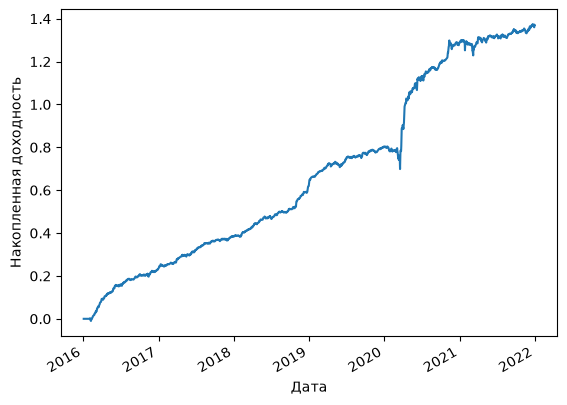

In [2]:
a1 = Alpha(Atractor())
a1.alpha_stats()

,sharpe,turnover,return,drawdown
2016,2.744294,0.023816,0.121998,0.017235
2017,1.094473,0.022687,0.035708,0.013495
2018,1.177182,0.022356,0.057915,0.027776
2019,1.378130,0.022006,0.072246,0.032453
2020,3.087038,0.034019,0.275237,0.046248
2021,2.632224,0.025643,0.175018,0.046474


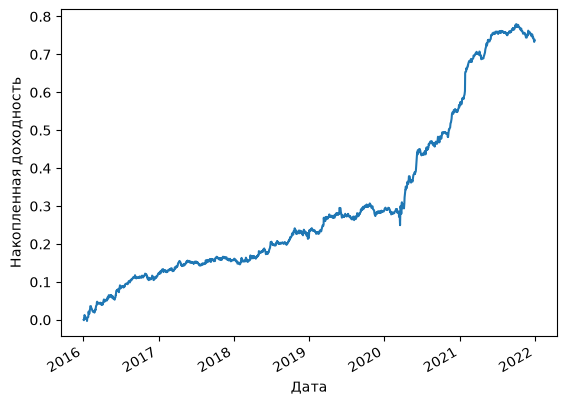

In [3]:
a2 = Alpha(InvClose(),cut_outliers=10,truncate=0.005)
a2.alpha_stats()

,sharpe,turnover,return,drawdown
2016,4.528015,0.672871,0.133778,0.011105
2017,4.674441,0.715339,0.101957,0.006259
2018,3.180047,0.709993,0.115039,0.030435
2019,3.735417,0.736949,0.101806,0.009488
2020,2.891128,0.714044,0.192985,0.048390
2021,4.290360,0.723536,0.146824,0.011526


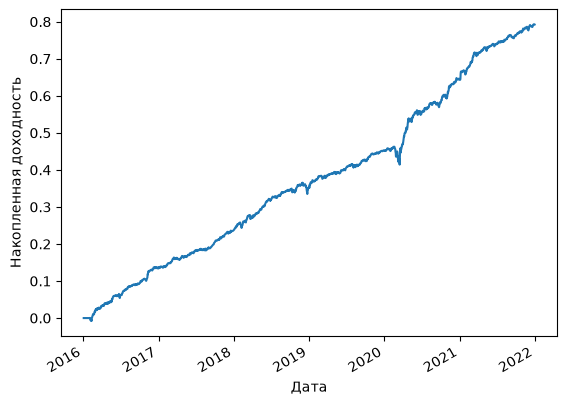

In [4]:
a3 = Alpha(HighShadow(),rank=True,decay=3)
a3.alpha_stats()

,sharpe,turnover,return,drawdown
2016,7.656381,0.676858,0.190676,0.005587
2017,7.393342,0.679940,0.149798,0.005269
2018,6.410806,0.683244,0.147372,0.005849
2019,5.888056,0.687923,0.160090,0.004946
2020,4.722976,0.697144,0.253062,0.026087
2021,4.194054,0.690466,0.135930,0.015098


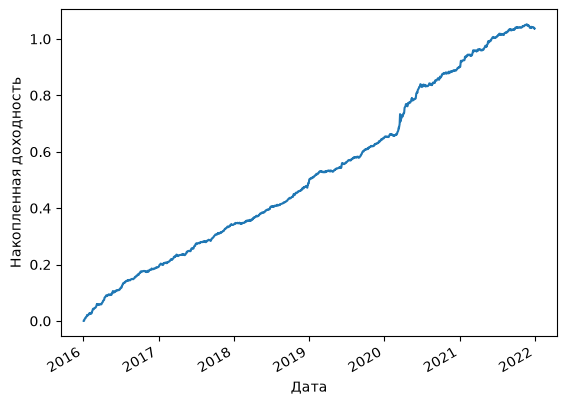

In [5]:
a4 = Alpha(UpperWick(),decay=5)
a4.alpha_stats()

,sharpe,turnover,return,drawdown
2016,5.886682,0.637451,0.118850,0.016957
2017,8.808002,0.707429,0.125832,0.003047
2018,5.260910,0.703675,0.118709,0.013476
2019,5.865072,0.698328,0.117890,0.009933
2020,6.772472,0.700477,0.255564,0.012651
2021,6.304666,0.695868,0.121221,0.005536


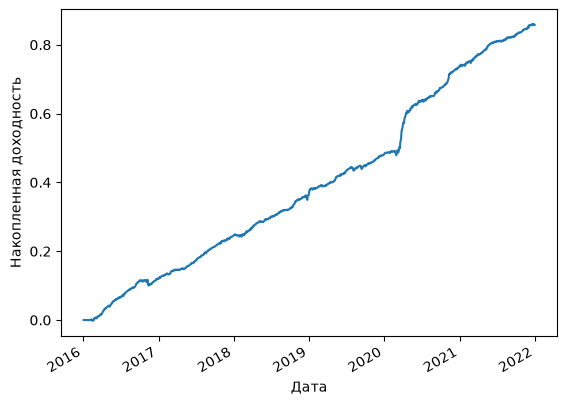

In [6]:
a5 = Alpha(Stoch(),decay=5)
a5.alpha_stats()

,sharpe,turnover,return,drawdown
2016,1.601344,0.637823,0.040824,0.014628
2017,2.387969,0.735925,0.045895,0.015542
2018,3.597894,0.725181,0.081027,0.010017
2019,3.714434,0.742252,0.083113,0.007415
2020,2.076090,0.718354,0.135665,0.034646
2021,2.432940,0.729502,0.086684,0.038565


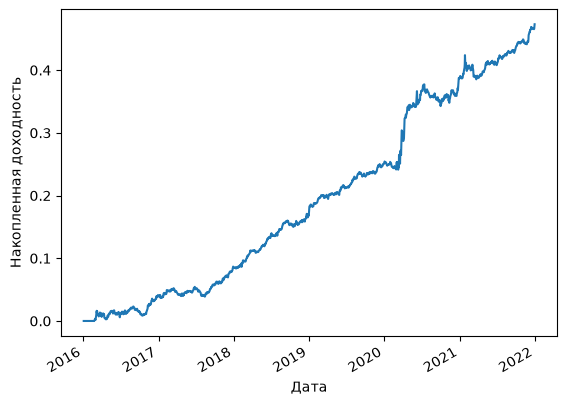

In [7]:
a6 = Alpha(VolumeRank(35),decay=2)
a6.alpha_stats()

In [8]:
alphas = [a1,a2,a3,a4,a5,a6]
rows = []
for a in alphas:
    others = [x for x in alphas if x is not a]
    res = a.check(others)
    res["sharpe"] = round(a.sharpe_ratio(),3)
    rows.append(res)
pd.DataFrame(rows,index=[f"a{i}" for i in range(1,7)])

,return,turnover,years_sharpe>=1,max_corr,passed,sharpe
a1,1.370,0.485,5,0.389,True,2.903
a2,0.738,0.025,6,0.363,True,2.098
a3,0.792,0.712,6,0.363,True,3.409
a4,1.037,0.686,6,0.204,True,5.366
a5,0.858,0.691,6,0.389,True,6.041
a6,0.473,0.715,6,0.132,True,2.224


In [9]:
pnls = pd.DataFrame({f"a{i}":a.pnl() for i,a in enumerate(alphas,1)})
pnls.corr()

,a1,a2,a3,a4,a5,a6
a1,1.000000,0.192149,0.139643,-0.197707,0.389299,0.076635
a2,0.192149,1.000000,-0.362733,-0.050092,0.104454,0.107886
a3,0.139643,-0.362733,1.000000,0.203655,0.229049,0.113845
a4,-0.197707,-0.050092,0.203655,1.000000,0.093701,-0.054541
a5,0.389299,0.104454,0.229049,0.093701,1.000000,0.132236
a6,0.076635,0.107886,0.113845,-0.054541,0.132236,1.000000


<Axes: xlabel='Дата', ylabel='Накопленная доходность'>

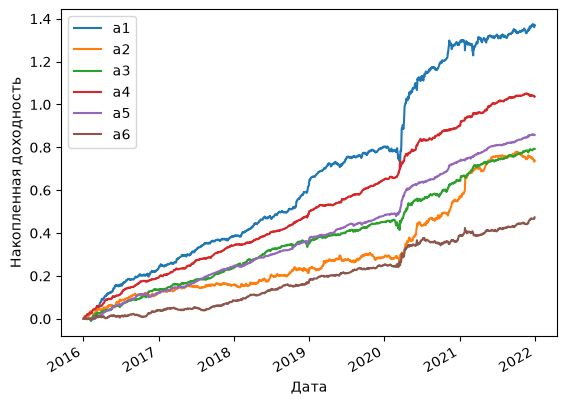

In [10]:
pnls.cumsum().plot(xlabel="Дата",ylabel="Накопленная доходность")